In [19]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import polars as pl
from utils.cleaning import *
from tree.xg_classifier import XGClassifier
from tree.custom_xgboost import CustomXGBClassifier
from xgboost import XGBClassifier, plot_tree
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, recall_score, auc, precision_score, roc_curve, average_precision_score, precision_recall_curve, confusion_matrix
from mini_shap.independent_tree_shap import IndependentTreeExplainer
import shap
from sklearn.utils.estimator_checks import check_estimator
from common.helper import load_data_and_scale_pos_weight
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
X_train, X_test, y_train, y_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True)

In [3]:
param_grid = {
    'learning_rate': [0.05, 0.1],
    'max_depth': [1, 2, 3],
    'n_estimators': [50, 100, 200],
}

In [4]:
cv = StratifiedKFold(
    n_splits=5,
)

In [5]:
xgb = CustomXGBClassifier(reg_lambda=1)

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=cv,
    n_jobs=-1,
    verbose=2,
    scoring="f1",
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END ...learning_rate=0.05, max_depth=1, n_estimators=50; total time=  11.5s
[CV] END ...learning_rate=0.05, max_depth=1, n_estimators=50; total time=  12.4s
[CV] END ...learning_rate=0.05, max_depth=1, n_estimators=50; total time=  12.2s
[CV] END ...learning_rate=0.05, max_depth=1, n_estimators=50; total time=  12.9s
[CV] END ...learning_rate=0.05, max_depth=1, n_estimators=50; total time=  13.7s
[CV] END ..learning_rate=0.05, max_depth=1, n_estimators=100; total time=  20.2s
[CV] END ..learning_rate=0.05, max_depth=1, n_estimators=100; total time=  21.2s
[CV] END ..learning_rate=0.05, max_depth=1, n_estimators=100; total time=  22.0s
[CV] END ..learning_rate=0.05, max_depth=1, n_estimators=100; total time=  20.9s
[CV] END ..learning_rate=0.05, max_depth=1, n_estimators=100; total time=  22.6s
[CV] END ...learning_rate=0.05, max_depth=2, n_estimators=50; total time=  21.6s
[CV] END ..learning_rate=0.05, max_depth=1, n_es

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",CustomXGBClas...(reg_lambda=1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [1, 2, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candi

In [6]:
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",CustomXGBClas...(reg_lambda=1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [1, 2, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candi

In [7]:
grid_search.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

In [8]:
grid_search.best_score_

np.float64(0.436896543667463)

In [9]:
grid_search.cv_results_

{'mean_fit_time': array([ 11.99922023,  20.50709853,  39.17571473,  20.53231192,
         37.49956121,  70.6559907 ,  34.70672464,  61.57417526,
        109.83889909,  14.8988534 ,  24.38037786,  42.37681093,
         22.0673811 ,  38.77619839,  68.91529179,  32.37848845,
         57.17156057,  78.75113206]),
 'std_fit_time': array([ 0.69132389,  0.81112834,  1.16942811,  0.31530193,  0.88583724,
         1.54686663,  1.52468506,  1.09070324,  1.17143933,  0.92360053,
         0.52205884,  0.90975316,  1.32929769,  1.4110567 ,  1.56098804,
         0.78198691,  3.02073102, 11.64153646]),
 'mean_score_time': array([0.54291353, 0.8461215 , 1.44130573, 0.79884834, 1.42589121,
        2.51693659, 1.12778816, 2.02607799, 3.46416106, 0.67327185,
        1.09648027, 1.44576044, 0.90290704, 1.41510224, 2.47669725,
        1.07628479, 1.72201829, 1.69269276]),
 'std_score_time': array([0.05133628, 0.05684875, 0.06394144, 0.03679944, 0.07372113,
        0.23739378, 0.06641872, 0.23310527, 0.2614

In [10]:
results_df = pd.DataFrame(grid_search.cv_results_)
results_df = results_df.sort_values(by=["rank_test_score"])
results_df = results_df.set_index(
    results_df["params"].apply(lambda x: "_".join(str(val) for val in x.values()))
).rename_axis("kernel")
results_df[["params", "rank_test_score", "mean_test_score", "std_test_score"]]

,params,rank_test_score,mean_test_score,std_test_score
kernel,,,,
0.1_3_200,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",1,0.436897,0.000941
0.1_2_200,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",2,0.436204,0.001318
0.1_3_100,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",3,0.435851,0.001074
0.05_3_200,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",4,0.435728,0.001049
0.05_2_200,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",5,0.434693,0.001159
0.1_2_100,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",6,0.434628,0.001361
0.1_3_50,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",7,0.433234,0.000920
0.1_1_200,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",8,0.433230,0.001109
0.05_3_100,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",9,0.432879,0.001057


In [11]:
results_df[["params", "rank_test_score", "mean_test_score", "std_test_score"]].to_csv("grid_search_result.csv")

In [12]:
# {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

final_model = XGBClassifier(
    max_depth=3, 
    learning_rate=0.1, 
    n_estimators=200,
    enable_categorical=True,
    random_state=1,
    reg_lambda=1,
    max_cat_to_onehot=1,
    min_child_weight=0,
    objective='binary:logistic',
    base_score=0.5,
    min_split_loss=0,
    verbose=0,
    scale_pos_weight=scale_pos_weight,
)

final_model.fit(X_train, y_train)

/home/sakane/Documents/projects/python/mini_xgshap/.venv/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [10:19:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",0.5
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method

In [16]:
y1_pred = final_model.predict(X_test)
y1_pred_proba = final_model.predict_proba(X_test)
acc1 = accuracy_score(y_test, y1_pred)
conf1 = confusion_matrix(y_test, y1_pred)
precis1 = precision_score(y_test, y1_pred)
rec1 = recall_score(y_test, y1_pred)
f11 = f1_score(y_test, y1_pred)
fpr1, tpr1, thresholds_roc1 = roc_curve(y_test, y1_pred_proba[:, 1])
roc_auc1 = auc(fpr1, tpr1)

prec1, recall1, th1 = precision_recall_curve(y_test, y1_pred_proba[:, 1])
prauc1 = auc(recall1, prec1)

In [17]:
print(
    f"""
Library Model
prediction = {y1_pred} 
pred_proba = {y1_pred_proba[:, 1]}
confusion matrix = 
{conf1}

accuracy = {acc1}
precision = {precis1}
recall = {rec1}
f1-score = {f11}
    """
)



Library Model
prediction = [0 0 1 ... 0 0 1] 
pred_proba = [0.05141845 0.12436373 0.62813467 ... 0.29565042 0.06952581 0.5136004 ]
confusion matrix = 
[[212546  84918]
 [ 12228  37646]]

accuracy = 0.7203127789070013
precision = 0.3071538135178356
recall = 0.7548221518225929
f1-score = 0.4366322968255257
    


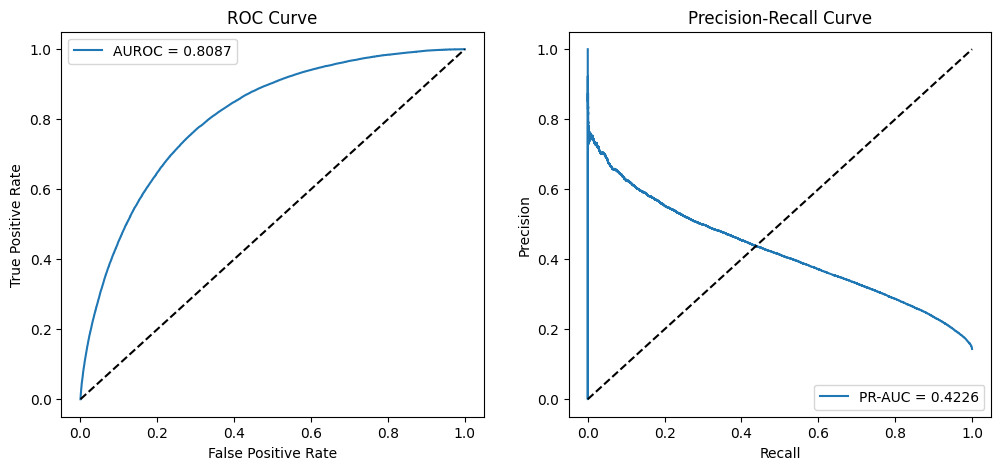

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(fpr1, tpr1, label=f'AUROC = {roc_auc1:.4f}')
ax[0].plot([0, 1], [0, 1], 'k--') # Random baseline
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC Curve')
ax[0].legend()

ax[1].plot(recall1, prec1, label=f'PR-AUC = {prauc1:.4f}')
ax[1].plot([0, 1], [0, 1], 'k--') # Random baseline
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()

plt.show()

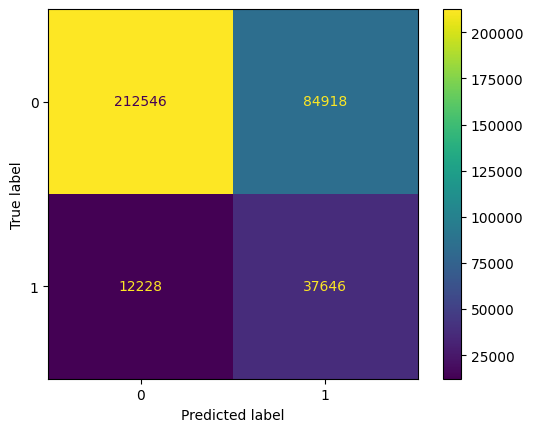

In [20]:
disp = ConfusionMatrixDisplay(conf1, display_labels=final_model.classes_)
disp.plot()

In [21]:
final_model.save_model("../model/final_model.ubj")